In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/student_mental_health.csv")
df.head()

df.tail()

df.sample(5)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
306,STU0307,24,Male,3,4.6,29.4,2.87,8.3,11.1,Moderate,7.6,9.6,75.3,No,Poor,No,High
823,STU0824,20,Female,2,8.6,16.0,2.43,6.1,7.9,Moderate,5.4,8.3,78.9,Yes,Good,Yes,Low
1530,STU1531,21,Female,3,4.9,29.1,3.08,6.3,10.2,Moderate,9.0,6.0,81.5,Yes,Average,Yes,High
1603,STU1604,19,Male,3,6.6,15.8,2.57,7.8,10.8,Low,7.6,3.2,85.8,No,Poor,Yes,High
1705,STU1706,20,Female,1,7.1,8.4,2.15,5.7,7.9,Low,7.8,7.0,91.1,Yes,Average,No,Medium


In [3]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [5]:
missing_vals = df.isna().sum()
missing_vals

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

In [6]:
X = df.drop(columns=["Mental_Health_Risk", "Student_ID"])

y = df["Mental_Health_Risk"]

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=42,
    stratify=y,
    test_size=0.20
)

In [8]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1600, 15)
X_test: (400, 15)
y_train: (1600,)
y_test: (400,)


In [9]:
numerical_cols = X_train.select_dtypes(
    include= np.number
).columns

categorical_cols = X_train.select_dtypes(
    include="object"
).columns

print("Numerical columns:", list(numerical_cols))
print("Categorical columns:", list(categorical_cols))

Numerical columns: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Categorical columns: ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


C:\Users\othma\AppData\Local\Temp\ipykernel_13296\1094103154.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


In [12]:
# %pip install scikit-learn
from sklearn.impute import SimpleImputer

num_impute = SimpleImputer(strategy="median")

X_train[numerical_cols] = num_impute.fit_transform(
    X_train[numerical_cols]
)

X_test[numerical_cols] = num_impute.transform(
    X_test[numerical_cols]
)


In [13]:
num_impute = SimpleImputer(strategy="most_frequent")

X_train[categorical_cols] = num_impute.fit_transform(
    X_train[categorical_cols]
)

X_test[categorical_cols] = num_impute.transform(
    X_test[categorical_cols]
)

In [14]:
print("Total missing values in X_train:",
      X_train.isnull().sum().sum())

print("Total missing values in X_test:",
      X_test.isnull().sum().sum())

Total missing values in X_train: 0
Total missing values in X_test: 0


In [15]:
cat_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns

print(list(cat_cols))

['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


C:\Users\othma\AppData\Local\Temp\ipykernel_13296\1505360809.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(


In [16]:
for col in categorical_cols:
    print(f"\nColumn: {col}")
    print(X_train[col].value_counts())


Column: Gender
Gender
Female        779
Male          746
Non-binary     75
Name: count, dtype: int64

Column: Physical_Activity
Physical_Activity
Moderate    742
Low         539
High        319
Name: count, dtype: int64

Column: Part_Time_Job
Part_Time_Job
No     1029
Yes     571
Name: count, dtype: int64

Column: Diet_Quality
Diet_Quality
Average    742
Poor       476
Good       382
Name: count, dtype: int64

Column: Previous_Mental_Health_History
Previous_Mental_Health_History
No     1140
Yes     460
Name: count, dtype: int64


In [17]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

encoder = OneHotEncoder()

preprossor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            encoder,
            categorical_cols
        )
    ]
)

X_train_encoded = preprossor.fit_transform(X_train)
X_test_encoded  = preprossor.transform(X_test)

In [18]:
print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

Training shape: (1600, 13)
Testing shape: (400, 13)


In [19]:
feature_names = preprossor.get_feature_names_out()

print(feature_names)

['categorical__Gender_Female' 'categorical__Gender_Male'
 'categorical__Gender_Non-binary' 'categorical__Physical_Activity_High'
 'categorical__Physical_Activity_Low'
 'categorical__Physical_Activity_Moderate' 'categorical__Part_Time_Job_No'
 'categorical__Part_Time_Job_Yes' 'categorical__Diet_Quality_Average'
 'categorical__Diet_Quality_Good' 'categorical__Diet_Quality_Poor'
 'categorical__Previous_Mental_Health_History_No'
 'categorical__Previous_Mental_Health_History_Yes']


In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train[numerical_cols]
)

In [21]:
print("Before scaling:")
print(X_train[numerical_cols].head())

print("\nAfter scaling:")
print(
    pd.DataFrame(
        X_train_scaled,
        columns=numerical_cols
    ).head()
)

Before scaling:
       Age  Year_of_Study  Sleep_Hours  Study_Hours_Per_Week   GPA  \
726   21.0            2.0          5.2                  18.6  2.59   
1384  23.0            1.0          4.9                  12.3  2.23   
1579  19.0            2.0          7.2                  17.0  2.21   
1098  23.0            1.0          8.3                  19.5  2.87   
582   22.0            3.0          7.2                  23.8  2.47   

      Social_Media_Hours  Screen_Time_Hours  Financial_Stress  Family_Support  \
726                  6.2               10.4               7.3             7.7   
1384                 6.4                8.9               4.4             7.2   
1579                 5.7                7.2               5.4             7.9   
1098                 6.9               10.4               7.5             4.8   
582                  5.6                8.0               7.2             7.8   

      Attendance_Rate  
726              76.1  
1384             81.7  
1579

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_cols
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [23]:
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("\nFeature names:")
print(preprocessor.get_feature_names_out())

Training shape: (1600, 23)
Testing shape: (400, 23)

Feature names:
['num__Age' 'num__Year_of_Study' 'num__Sleep_Hours'
 'num__Study_Hours_Per_Week' 'num__GPA' 'num__Social_Media_Hours'
 'num__Screen_Time_Hours' 'num__Financial_Stress' 'num__Family_Support'
 'num__Attendance_Rate' 'cat__Gender_Female' 'cat__Gender_Male'
 'cat__Gender_Non-binary' 'cat__Physical_Activity_High'
 'cat__Physical_Activity_Low' 'cat__Physical_Activity_Moderate'
 'cat__Part_Time_Job_No' 'cat__Part_Time_Job_Yes'
 'cat__Diet_Quality_Average' 'cat__Diet_Quality_Good'
 'cat__Diet_Quality_Poor' 'cat__Previous_Mental_Health_History_No'
 'cat__Previous_Mental_Health_History_Yes']


In [24]:
print("Missing values in original training data:")
print(X_train.isnull().sum().sum())

print("\nMissing values in processed training data:")
print(np.isnan(X_train_processed).sum())

Missing values in original training data:
0

Missing values in processed training data:
0


In [25]:
y_train.value_counts()

Mental_Health_Risk
High      544
Medium    528
Low       528
Name: count, dtype: int64

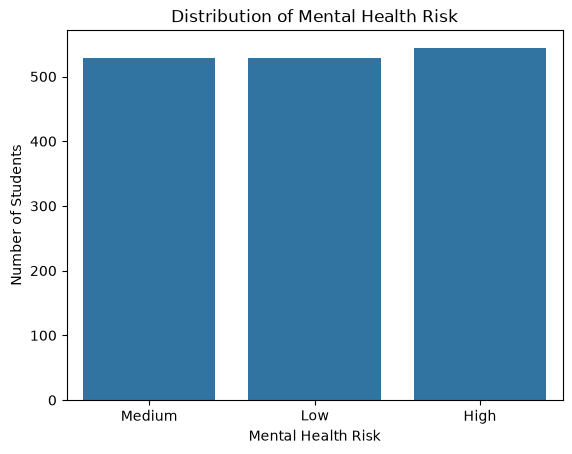

In [26]:
sns.countplot(x=y_train)

plt.title("Distribution of Mental Health Risk")
plt.xlabel("Mental Health Risk")
plt.ylabel("Number of Students")

plt.show()

In [27]:
X = df.drop(columns=["Mental_Health_Risk", "Student_ID"])
y = df["Mental_Health_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [28]:
numerical_cols = X_train.select_dtypes(
    include=np.number
).columns

categorical_cols = X_train.select_dtypes(
    exclude=np.number
).columns

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [30]:
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [31]:
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [32]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_pipeline,
            numerical_cols
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_cols
        )
    ]
)

In [33]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [34]:
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("\nFeature names:")
print(preprocessor.get_feature_names_out())


Training shape: (1600, 23)
Testing shape: (400, 23)

Feature names:
['num__Age' 'num__Year_of_Study' 'num__Sleep_Hours'
 'num__Study_Hours_Per_Week' 'num__GPA' 'num__Social_Media_Hours'
 'num__Screen_Time_Hours' 'num__Financial_Stress' 'num__Family_Support'
 'num__Attendance_Rate' 'cat__Gender_Female' 'cat__Gender_Male'
 'cat__Gender_Non-binary' 'cat__Physical_Activity_High'
 'cat__Physical_Activity_Low' 'cat__Physical_Activity_Moderate'
 'cat__Part_Time_Job_No' 'cat__Part_Time_Job_Yes'
 'cat__Diet_Quality_Average' 'cat__Diet_Quality_Good'
 'cat__Diet_Quality_Poor' 'cat__Previous_Mental_Health_History_No'
 'cat__Previous_Mental_Health_History_Yes']


In [35]:
print("Missing values in training:",
      np.isnan(X_train_processed).sum())

print("Missing values in testing:",
      np.isnan(X_test_processed).sum())

Missing values in training: 0
Missing values in testing: 0


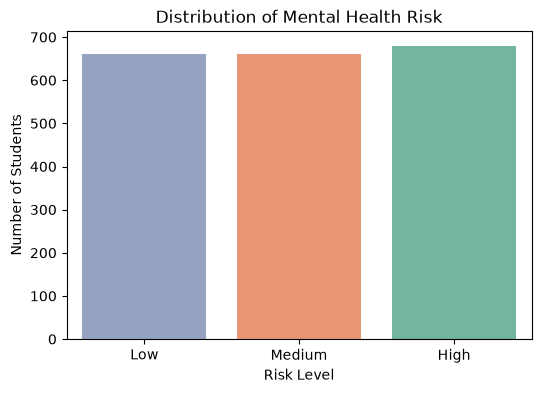

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(
    data=df,
    x="Mental_Health_Risk",
    order=["Low", "Medium", "High"],
    hue="Mental_Health_Risk",
    palette="Set2",
    legend=False
)
plt.title("Distribution of Mental Health Risk")
plt.xlabel("Risk Level")
plt.ylabel("Number of Students")
plt.show()

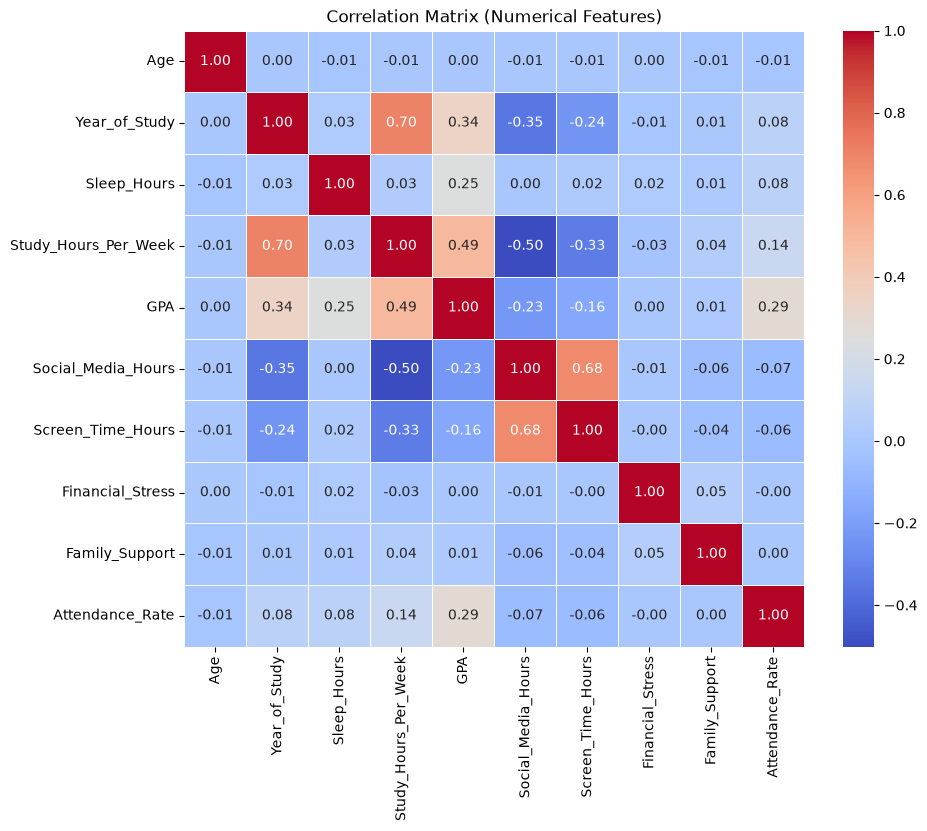

In [40]:
plt.figure(figsize=(10, 8))
corr_matrix = df[numerical_cols].corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)
plt.title("Correlation Matrix (Numerical Features)")
plt.show()

C:\Users\othma\AppData\Local\Temp\ipykernel_13296\3342801578.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Mental_Health_Risk", y="Sleep_Hours", order=["Low", "Medium", "High"], palette="Set2", ax=axes[0])
C:\Users\othma\AppData\Local\Temp\ipykernel_13296\3342801578.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Mental_Health_Risk", y="Financial_Stress", order=["Low", "Medium", "High"], palette="Set2", ax=axes[1])
C:\Users\othma\AppData\Local\Temp\ipykernel_13296\3342801578.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same eff

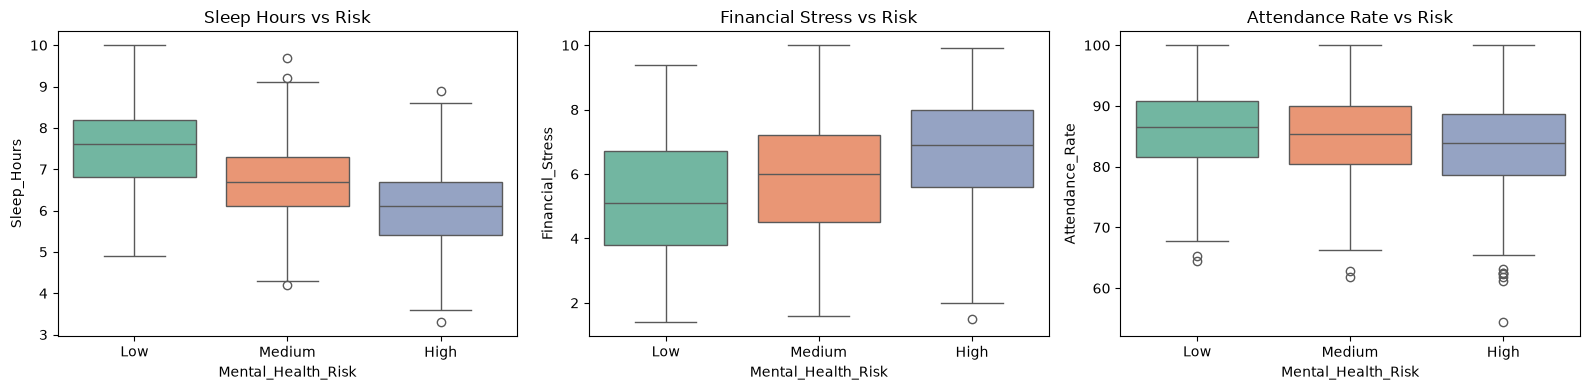

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(data=df, x="Mental_Health_Risk", y="Sleep_Hours", order=["Low", "Medium", "High"], palette="Set2", ax=axes[0])
axes[0].set_title("Sleep Hours vs Risk")

sns.boxplot(data=df, x="Mental_Health_Risk", y="Financial_Stress", order=["Low", "Medium", "High"], palette="Set2", ax=axes[1])
axes[1].set_title("Financial Stress vs Risk")

sns.boxplot(data=df, x="Mental_Health_Risk", y="Attendance_Rate", order=["Low", "Medium", "High"], palette="Set2", ax=axes[2])
axes[2].set_title("Attendance Rate vs Risk")

plt.tight_layout()
plt.show()

In [42]:
# Cell 3: Save Processed Train/Test Splits (Matches data_preprocessing.py)
import os
os.makedirs("../data/processed", exist_ok=True)

# Re-load raw split to keep raw structure for the Scikit-Learn Pipeline
raw_X = df.drop(columns=["Mental_Health_Risk", "Student_ID"])
raw_y = df["Mental_Health_Risk"]

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    raw_X, raw_y, test_size=0.20, random_state=42, stratify=raw_y
)

train_data = X_train_raw.copy()
train_data["Mental_Health_Risk"] = y_train_raw
train_data.to_csv("../data/processed/train.csv", index=False)

test_data = X_test_raw.copy()
test_data["Mental_Health_Risk"] = y_test_raw
test_data.to_csv("../data/processed/test.csv", index=False)

print("Saved train.csv and test.csv successfully!")

Saved train.csv and test.csv successfully!
